# LC091 | Figure 4

Saved SHINE results. Training seed 123; K=5; clustering seed 0.

Five-fit summaries use seeds 0, 1, 2, 123 and 1234. See [setup and data requirements](README.md).

In [1]:
import os
for key in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMBA_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ[key] = "1"
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "1")
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import shine
from shine import SHINE, normalize_counts
from shine.study import Section
from shine.plotting import spatial_results, regional_results, molecular_maps, attention_plot, save_panel

CASE = "LC091"
# Extract the figure-data archive into data/, or set SHINE_DATA_ROOT.
search_roots = [Path.cwd(), *Path.cwd().parents]
if os.environ.get("SHINE_DATA_ROOT"):
    ROOT = Path(os.environ["SHINE_DATA_ROOT"]).expanduser().resolve()
else:
    ROOT = next((candidate for parent in search_roots
                 for candidate in (parent / "data", parent)
                 if (candidate / "revision_experiments").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Extract the figure-data archive into data/, or set SHINE_DATA_ROOT. See data/README.md.")
manifest_candidates = [p / name for p in search_roots
                       for name in ("sections.json", "notebooks/sections.json")]
manifest_candidates.append(ROOT / "SHINE-github/notebooks/sections.json")
MANIFEST = next((p for p in manifest_candidates if p.is_file()), None)
if MANIFEST is None:
    raise FileNotFoundError("Cannot find notebooks/sections.json.")
OUT = ROOT / "outputs/notebook_results_20261124" / CASE
OUT.mkdir(parents=True, exist_ok=True)
section = Section(ROOT, MANIFEST, CASE)
print("shine-omics", shine.__version__, "|", CASE, "|", len(section.spots), "paired spots")

shine-omics 0.1.0.dev1 | LC091 | 2141 paired spots


## 1. Settings

Fixed figure settings and paired cohort. Source files are verified by SHA-256.

In [2]:
settings = {"Figure": section.config["figure"], "K": section.config["K"],
            "epochs": 120, "training_seed": 123,
            "clustering_seed": section.config["display_clustering_seed"],
            "final_ReLU": True, **section.config["model_options"]}
display(pd.Series(settings, name="Final setting").to_frame())
display(section.spots.groupby(["region", "lesion"], dropna=False).size().rename("paired_spots").reset_index())

,Final setting
Figure,4
K,5
epochs,120
training_seed,123
clustering_seed,0
final_ReLU,True
loss,reconstruction
l2,False
spatial_floor,0.5
latent_dim,128


,region,lesion,paired_spots
0,Airway,NaN,158
1,Blood vessel,NaN,29
2,Lymphocytes,NaN,27
3,Normal cells,NaN,1307
4,Tumor,NaN,548
5,Unlabelled,NaN,72


## 2. Inputs

These paired matrices are already preprocessed. Do not repeat normalization or registration.

In [3]:
print(section.config["preprocessing"])
input_audit = pd.DataFrame([
    {"modality": name, "spots": x.shape[0], "features": x.shape[1],
     "finite": bool(np.isfinite(x).all()), "constant_rows": int((x.std(1) == 0).sum()),
     "minimum": float(x.min()), "maximum": float(x.max())}
    for name, x in [("RNA", section.rna), ("MSI", section.msi)]])
display(input_audit)
assert section.spots.spot.is_unique
assert np.allclose(section.xy, section.spots[["x", "y"]])
# For raw counts: normalize_counts(full_counts, feature_indices=frozen_columns)
# Do not renormalize section.rna or section.msi.

Frozen original notebook paired matrices; RNA QC and HVG selection, RNA/MSI total/TIC 10000/log1p were done upstream. No repeat normalization. Features and barcodes are hash-verified.


,modality,spots,features,finite,constant_rows,minimum,maximum
0,RNA,2141,2000,True,0,0.0,8.624078
1,MSI,2141,2082,True,0,0.0,7.234732


## 3. Graphs

H5 + H20; spatial kNN6; feature correlation-kNN20; local self+6 attention. Graphs use no annotation labels.

In [4]:
data, graphs = section.prepare()
display(pd.Series(graphs["audit"], name="Graph audit").to_frame())
print("Validated tensor shape:", data.shape)
print("Input + graph fingerprint:", data.fingerprint())

<reference-environment>/site-packages/threadpoolctl.py:1214: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)


,Graph audit
n_spots,2141
spatial_k,6
feature_k,20
hyperedge_sizes,"[5, 20]"
n_hyperedges,4282
pca_components,30
pca_seed,0
constant_feature_rows,"[0, 0]"
allow_constant_feature_rows,True
labels_used,False


Validated tensor shape: (2141, 2000, 2082)
Input + graph fingerprint: e65176839d1da1c0df4b7cbc920d00ecea7f829c473cddb3089bf8582df944a1


## 4. Model

Replay the saved figure model. Set `RUN_NEW_TRAINING=True` for a separate 120-epoch fit.

In [5]:
model, labels, replay_audit = section.replay(data)
display(pd.Series(replay_audit).to_frame("Replay check"))
RUN_NEW_TRAINING = False
if RUN_NEW_TRAINING:
    new_model = SHINE(**section.config["model_options"])
    def progress(record):
        if record["epoch"] % 20 == 0:
            print("Epoch", record["epoch"], "loss", round(record["total"], 5))
    new_model.fit(data, epochs=120, seed=123, lr=1e-4, weight_decay=1e-3, progress=progress)
    new_labels = new_model.cluster(section.config["K"], seed=section.config["display_clustering_seed"])
    new_model.save(OUT / "new_training_seed123.pt")
    display(section.score(new_labels))
else:
    print("Displaying the saved figure model.")

,Replay check
embedding_max_abs_error,0.0
figure_labels_exact,True
n_spots,2141
origin,saved figure checkpoint; new package inference


Displaying the saved figure model.


## 5. ARI and NMI

Average five clustering seeds within each fit, then report mean and sample SD over five training seeds. Regional scores retain whole-section cluster IDs.

In [6]:
display_metrics = section.score(labels)
raw_metrics, per_fit, summary = section.five_fit_metrics()
print("Displayed fit: seed 123")
display(display_metrics.round(4))
print("Five fits: mean and sample SD")
display(summary.round(4))
display(per_fit.round(4))
for name, table in [("display_metrics", display_metrics), ("all_partitions", raw_metrics),
                    ("per_training_fit", per_fit), ("five_fit_summary", summary)]:
    table.to_csv(OUT / (name + ".csv"), index=False)

Displayed fit: seed 123


,endpoint,n_scored,ARI,NMI
0,Whole section,2069,0.3412,0.4596


Five fits: mean and sample SD


,endpoint,ARI_mean,ARI_std,NMI_mean,NMI_std,n_fits
0,Whole section,0.345,0.0071,0.4609,0.0056,5


,endpoint,training_seed,ARI,NMI
0,Whole section,0,0.3527,0.4640
1,Whole section,1,0.3346,0.4530
2,Whole section,2,0.3474,0.4598
3,Whole section,123,0.3414,0.4597
4,Whole section,1234,0.3489,0.4679


## 6. Spatial partition and UMAP

Colors are matched to annotations for display only. UMAP is not used for clustering or scoring.

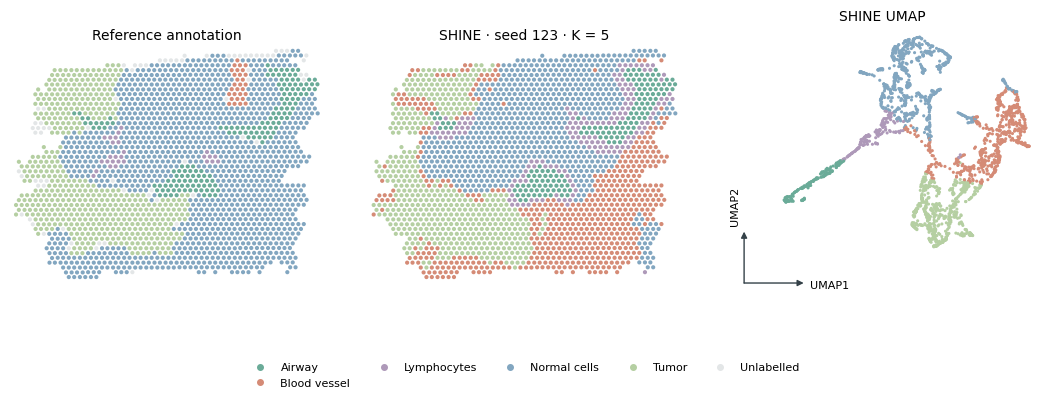

In [7]:
import umap
saved_embedding = np.load(section.path("embedding_123"))
umap_xy = umap.UMAP(n_neighbors=15, min_dist=0.3, random_state=123, n_jobs=1).fit_transform(saved_embedding)
fig = spatial_results(section, labels, umap_xy)
save_panel(fig, OUT / "seed123_spatial_UMAP")
plt.show()
spatial_source = section.spots.copy()
spatial_source["SHINE_cluster"] = labels
spatial_source[["UMAP1", "UMAP2"]] = umap_xy
spatial_source.to_csv(OUT / "seed123_spatial_source.csv", index=False)

## 7. Attention

Spatial-branch weights within RNA and MSI. These are mixing weights, not causal importance.

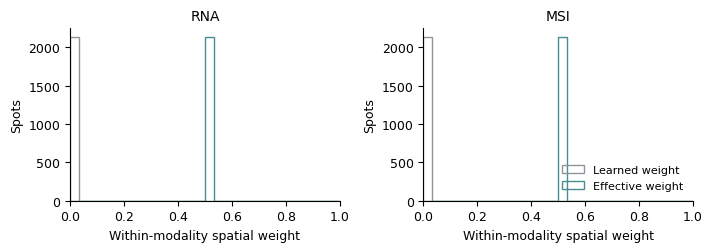

,RNA_spatial_raw,RNA_spatial_effective,MSI_spatial_raw,MSI_spatial_effective
count,2141.000,2141.000,2141.000,2141.000
mean,0.010,0.505,0.014,0.507
std,0.003,0.001,0.001,0.001
min,0.004,0.502,0.010,0.505
25%,0.008,0.504,0.013,0.506
50%,0.010,0.505,0.014,0.507
75%,0.011,0.506,0.014,0.507
max,0.024,0.512,0.018,0.509


In [8]:
fig = attention_plot(model)
save_panel(fig, OUT / "attention_weights")
plt.show()
attention_source = pd.DataFrame({"spot": section.spots.spot,
    "RNA_spatial_raw": model.attention_["rna_raw"][:, 0],
    "RNA_spatial_effective": model.attention_["rna"][:, 0],
    "MSI_spatial_raw": model.attention_["msi_raw"][:, 0],
    "MSI_spatial_effective": model.attention_["msi"][:, 0]})
attention_source.to_csv(OUT / "attention_source.csv", index=False)
display(attention_source.drop(columns="spot").describe().round(3))

## 8. Measured genes and MSI peaks

Six genes and six peaks with the largest positive rank-biserial effects for tumor-enriched cluster C0 versus other spots. Peak identities require separate evidence.

RNA: ['S100P', 'ATP1B1', 'EPCAM', 'CRLF1', 'BARX1', 'AQP5']
MSI m/z: ['mz_867.5191735166386', 'mz_843.5243941169788', 'mz_869.5345667951163', 'mz_462.2989812223153', 'mz_539.1376623683047', 'mz_617.1536811704982']


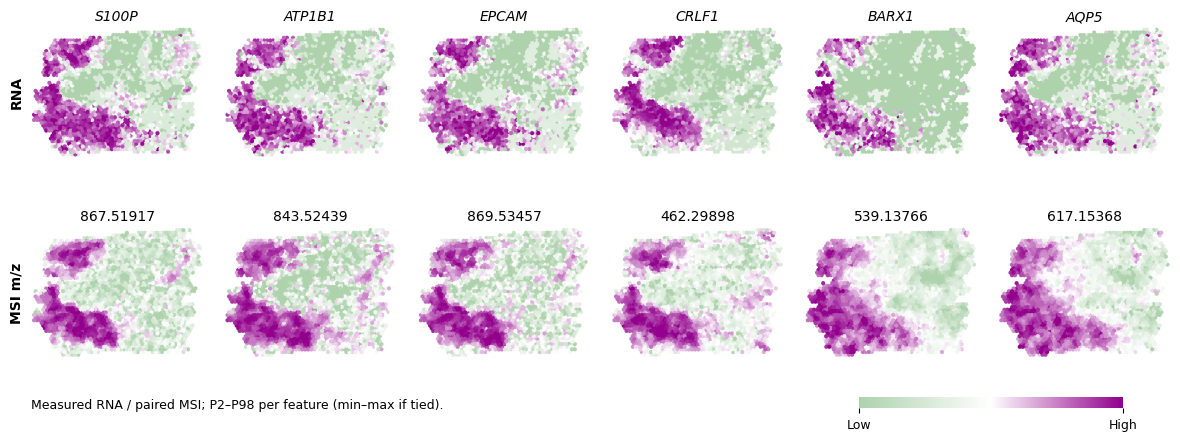

,contrast,feature,n_reference,n_target,mean_reference,mean_target,difference_SD
0,C0 versus rest,S100P,1615,526,0.975,2.738,1.706
1,C0 versus rest,ATP1B1,1615,526,0.856,2.475,1.720
2,C0 versus rest,EPCAM,1615,526,0.783,2.325,1.695
3,C0 versus rest,CRLF1,1615,526,0.862,3.135,1.808
4,C0 versus rest,BARX1,1615,526,0.277,1.778,1.821
5,C0 versus rest,AQP5,1615,526,0.847,2.352,1.629
6,C0 versus rest,mz_867.5191735166386,1615,526,1.122,2.750,1.673
7,C0 versus rest,mz_843.5243941169788,1615,526,1.390,3.036,1.486
8,C0 versus rest,mz_869.5345667951163,1615,526,1.238,2.743,1.576
9,C0 versus rest,mz_462.2989812223153,1615,526,1.253,2.226,1.535


In [9]:
molecules = section.molecular_values()
print("RNA:", section.config["display_genes"])
print("MSI m/z:", section.config["display_peaks"])
fig = molecular_maps(section, molecules)
save_panel(fig, OUT / "measured_molecules")
plt.show()
measured_source = pd.concat([section.spots[["spot", "x", "y", "region", "lesion"]], molecules], axis=1)
measured_source.to_csv(OUT / "measured_molecule_source.csv", index=False)
effects = section.molecular_comparison(molecules, labels)
display(effects.round(3))
effects.to_csv(OUT / "measured_molecule_effects.csv", index=False)

## 9. Molecular selection

Selected cluster, effect direction and ranking from the figure source tables.

In [10]:
for modality in ["rna", "msi"]:
    section.verify(modality + "_selection")
    print(modality.upper())
    display(pd.read_csv(section.path(modality + "_selection")))

RNA


,cluster,feature,rank_effect,mean_difference,standardized_difference
0,0,S100P,0.955101,1.762718,1.706429
1,0,ATP1B1,0.943676,1.619820,1.719836
2,0,EPCAM,0.942192,1.542333,1.694869
3,0,CRLF1,0.937142,2.272836,1.808158
4,0,BARX1,0.914636,1.500730,1.821368
5,0,AQP5,0.913259,1.504859,1.628920


MSI


,cluster,feature,rank_effect,mean_difference,standardized_difference
0,0,mz_867.5191735166386,0.901367,1.628106,1.673113
1,0,mz_843.5243941169788,0.895351,1.646104,1.485820
2,0,mz_869.5345667951163,0.893908,1.504767,1.576173
3,0,mz_462.2989812223153,0.861597,0.973072,1.535132
4,0,mz_539.1376623683047,0.846906,0.811158,1.467714
5,0,mz_617.1536811704982,0.836050,0.888539,1.422205


## 10. Validation and exports

Saved-model replay and fresh training are reported separately. Fresh fits do not replace the figure model.

In [6]:
validation_dir = ROOT / "outputs/shine_omics_notebooks_validation_20261124" / CASE
for filename in ["replay_validation.json", "fresh_training_validation.json"]:
    path = validation_dir / filename
    if path.exists():
        display(pd.Series(json.loads(path.read_text()), name=filename).to_frame())
    else:
        print(filename, "Not available; training validation is incomplete.")
provenance = {"case": CASE, "package_version": shine.__version__, "settings": settings,
              "replay": replay_audit, "sources": section.config["sources"],
              "statistical_unit": "training seed; sample SD over five fits",
              "spatial_train_seed": 123, "new_training_replaces_figure": False}
(OUT / "notebook_provenance.json").write_text(json.dumps(provenance, indent=2))
print("Output directory:", OUT)

,replay_validation.json
embedding_max_abs_error,0.0
figure_labels_exact,True
n_spots,2141
origin,saved figure checkpoint; new package inference
graph_audit,"{'n_spots': 2141, 'spatial_k': 6, 'feature_k':..."
data_fingerprint,e65176839d1da1c0df4b7cbc920d00ecea7f829c473cdd...
seconds,16.574598


,fresh_training_validation.json
case,LC091
epochs,120
training_seed,123
seconds,397.351212
finite_embedding,True
fresh_vs_historical_max_abs_error,0.000005
partition_ARI_vs_historical,1.0
main_figure_overwritten,False


Output directory: $SHINE_DATA_ROOT/outputs/notebook_results_20261124/LC091
